# 12 - Matplotlib avanzado — **Soluciones + Autotests**


Incluye ejemplos resueltos de:
- Subplots y **GridSpec**.
- **Anotaciones**, líneas de referencia.
- Ejes secundarios y escalas.
- Barras apiladas y proporciones.
- Exportación de figuras.


## 1) Dataset sintético

In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n = 300
df = pd.DataFrame({
    "x": np.linspace(0, 10, n),
    "y": np.sin(np.linspace(0, 10, n)) + rng.normal(0, 0.2, n),
    "cat": rng.choice(["A", "B", "C"], size=n),
    "valor": rng.normal(100, 20, n).round(1)
})
df.shape

(300, 4)

## 2) Subplots con GridSpec

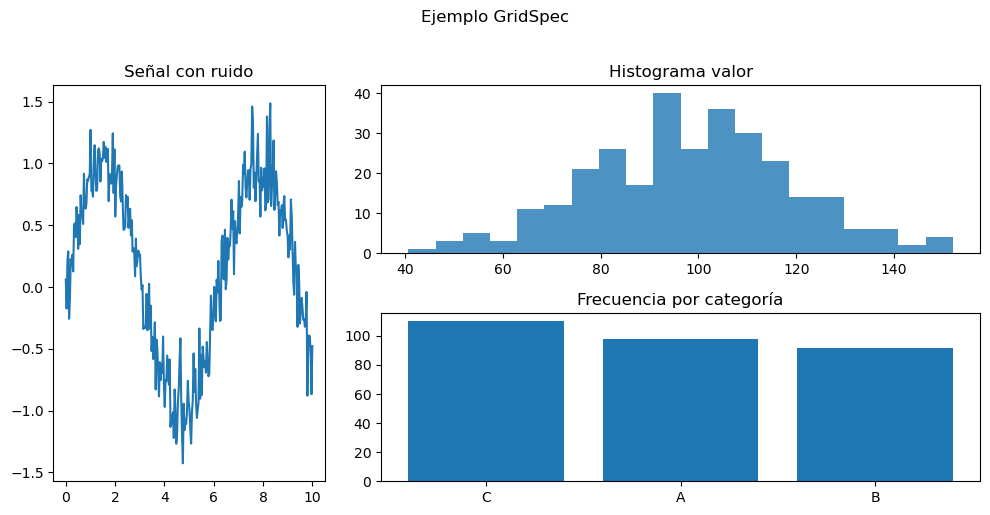

In [6]:

fig = plt.figure(figsize=(10, 5))
gs = fig.add_gridspec(2, 3)
ax1 = fig.add_subplot(gs[:, 0])
ax2 = fig.add_subplot(gs[0, 1:])
ax3 = fig.add_subplot(gs[1, 1:])

ax1.plot(df["x"], df["y"]); ax1.set_title("Señal con ruido")
ax2.hist(df["valor"], bins=20, alpha=0.8); ax2.set_title("Histograma valor")
ax3.bar(df["cat"].value_counts().index, df["cat"].value_counts().values)
ax3.set_title("Frecuencia por categoría")
fig.suptitle("Ejemplo GridSpec", y=1.02)
fig.tight_layout()
plt.show()

## 3) Anotaciones y líneas de referencia

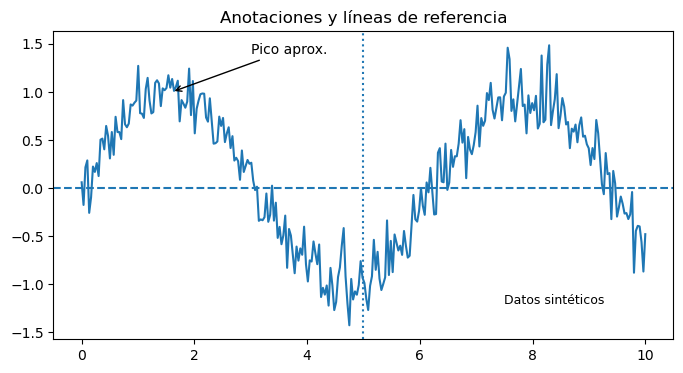

In [7]:

fig, ax = plt.subplots(figsize=(8,4))
ax.plot(df["x"], df["y"])
ax.axhline(0, linestyle="--")
ax.axvline(5, linestyle=":")
ax.annotate("Pico aprox.", xy=(1.6, 1.0), xytext=(3, 1.4), arrowprops=dict(arrowstyle="->"))
ax.text(7.5, -1.2, "Datos sintéticos", fontsize=9)
ax.set_title("Anotaciones y líneas de referencia")
plt.show()

## 4) Eje secundario y escala log

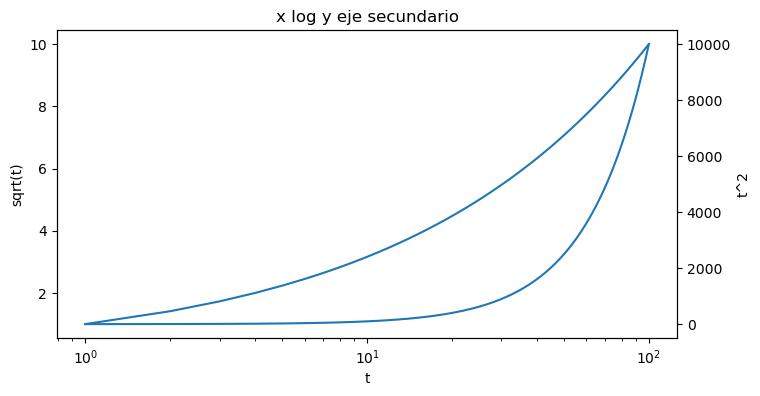

In [8]:

t = np.linspace(1, 100, 100)
f = np.sqrt(t)
fig, ax1 = plt.subplots(figsize=(8,4))
ax1.plot(t, f)
ax1.set_xlabel("t")
ax1.set_ylabel("sqrt(t)")
ax2 = ax1.twinx()
ax2.plot(t, t**2)
ax2.set_ylabel("t^2")
ax1.set_xscale("log")
ax1.set_title("x log y eje secundario")
plt.show()

## 5) Barras apiladas y proporciones

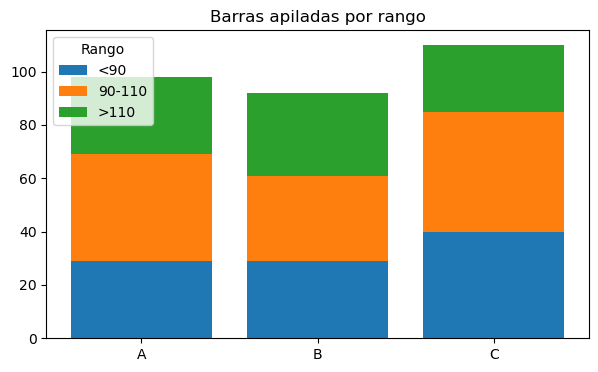

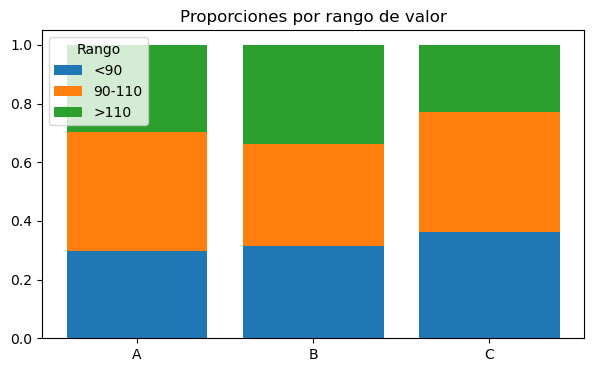

In [ ]:

tabla = pd.crosstab(df["cat"], pd.cut(df["valor"], bins=[0,90,110,200], labels=["<90","90-110",">110"]))
tabla_prop = (tabla.T / tabla.T.sum()).T

fig, ax = plt.subplots(figsize=(7,4))
bottom = np.zeros(len(tabla))
for col in tabla.columns:
    ax.bar(tabla.index, tabla[col].values, bottom=bottom, label=col)
    bottom += tabla[col].values
ax.set_title("Barras apiladas por rango")
ax.legend(title="Rango")
plt.show()

fig, ax = plt.subplots(figsize=(7,4))
bottom = np.zeros(len(tabla_prop))
for col in tabla_prop.columns:
    ax.bar(tabla_prop.index, tabla_prop[col].values, bottom=bottom, label=col)
    bottom += tabla_prop[col].values
ax.set_title("Proporciones por rango de valor")
ax.legend(title="Rango")
plt.show()

## 6) Exportar figura

'./visualizacion_fig.png'

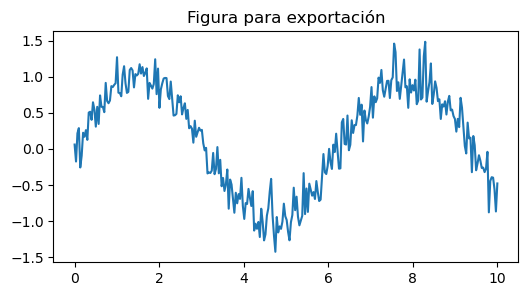

In [11]:

fig, ax = plt.subplots(figsize=(6,3))
ax.plot(df["x"], df["y"])
ax.set_title("Figura para exportación")
ruta_png = "./visualizacion_fig.png"
fig.savefig(ruta_png, dpi=200, bbox_inches="tight")
ruta_png

---

## ✅ Autotests 12

In [ ]:

from pathlib import Path

def check(cond, ok, fail):
    if cond: print("✔", ok)
    else: raise AssertionError("✘ " + fail)

# Test 1: dataset con filas y columnas esperadas
check(df.shape[0] == 300 and set(df.columns) == {"x","y","cat","valor"},
      "Dataset df correcto (300 filas, columnas x,y,cat,valor).",
      f"Estructura de df inesperada: {df.shape}, {df.columns.tolist()}")

# Test 2: tablas de barras creadas
check('tabla' in globals() and 'tabla_prop' in globals(),
      "Tablas 'tabla' y 'tabla_prop' creadas.", "Faltan tablas para las barras.")

# Test 3: figura exportada existe
check(Path(ruta_png).exists(), f"Figura exportada en {ruta_png}.", "No se encontró el archivo exportado.")